# FastSpeech 2 training, Telugu

Trains the Telugu model on a Colab A100 GPU and compares the saved checkpoints with Whisper.
Run all cells and paste a Hugging Face token with write access when asked.

The code and preprocessed features come from the private dataset repo `gsri-18/fs2-iiith-data`. Checkpoints
and loss logs are uploaded to `gsri-18/fastspeech2-en-te-checkpoints` as they are saved, so after a disconnect,
running all cells again continues from the newest checkpoint. Every cell prints the time it finished (IST) and
how long it took.

In [1]:
LANG = "Telugu"
DATA_REPO = "gsri-18/fs2-iiith-data"
CKPT_REPO = "gsri-18/fastspeech2-en-te-checkpoints"

import datetime, os, time

IST = datetime.timezone(datetime.timedelta(hours=5, minutes=30))
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

if "_cell_timer" not in globals():
    def _cell_start(info):
        globals()["_cell_t0"] = time.time()

    def _cell_end(result):
        took = time.time() - globals().get("_cell_t0", time.time())
        print(f"[{datetime.datetime.now(IST):%Y-%m-%d %H:%M:%S} IST] finished in {took:.1f} s")

    get_ipython().events.register("pre_run_cell", _cell_start)
    get_ipython().events.register("post_run_cell", _cell_end)
    _cell_timer = True

[2026-11-01 20:08:32 IST] finished in -0.0 s


## Setup

In [2]:
import sys, torch
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader
print(f"Python {sys.version.split()[0]}, PyTorch {torch.__version__}, CUDA {torch.version.cuda}, {os.cpu_count()} CPU cores")

NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07
Python 3.13.16, PyTorch 2.11.0+cu130, CUDA 13.0, 12 CPU cores
[2026-11-01 20:08:36 IST] finished in 3.9 s


In [3]:
import getpass
if not os.environ.get("HF_TOKEN"):
    os.environ["HF_TOKEN"] = getpass.getpass("Hugging Face token (write access): ").strip()
from huggingface_hub import whoami
print("logged in as", whoami()["name"])

Hugging Face token (write access): ··········
logged in as gsri-18
[2026-11-01 20:08:41 IST] finished in 4.6 s


In [4]:
import zipfile
from huggingface_hub import hf_hub_download

for name in ["code.zip", f"{LANG}_preprocessed.zip"]:
    path = hf_hub_download(DATA_REPO, name, repo_type="dataset", force_download=(name == "code.zip"))
    zipfile.ZipFile(path).extractall("/content/project")
print("code version", open("/content/project/COMMIT").read().strip())
!wc -l /content/project/{LANG}/preprocessed_data/train.txt /content/project/{LANG}/preprocessed_data/val.txt

code version b23243b
   2625 /content/project/Telugu/preprocessed_data/train.txt
    531 /content/project/Telugu/preprocessed_data/val.txt
   3156 total
[2026-11-01 20:08:56 IST] finished in 14.9 s


In [5]:
!pip -q install "setuptools<81" pyworld tgt g2p_en inflect unidecode

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[2026-11-01 20:09:31 IST] finished in 34.8 s


## Training

In [6]:
%cd /content/project/{LANG}
!grep -A5 "^  step:" config.yaml
!python -W ignore train.py --resume --hub_repo {CKPT_REPO} --num_workers 4 --quiet

/content/project/Telugu
  step:
    total_step: 12000        # a first run at batch 16 peaked after about 200k sentences, about 4k steps here
    log_step: 100
    synth_step: 2000
    val_step: 500
    save_step: 1000
I0000 00:00:1793543973.697193    1319 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793543975.996767    1319 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793543975.997369    1319 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
no checkpoint found, starting fresh
[2026-11-01 20:09:40 IST] Prepare training ... (device: cud

## Loss curves

/content/project
Telugu: 120 train logs, 24 val points, best val total 2.1063 at step 8500, last val 2.1088 at step 12000


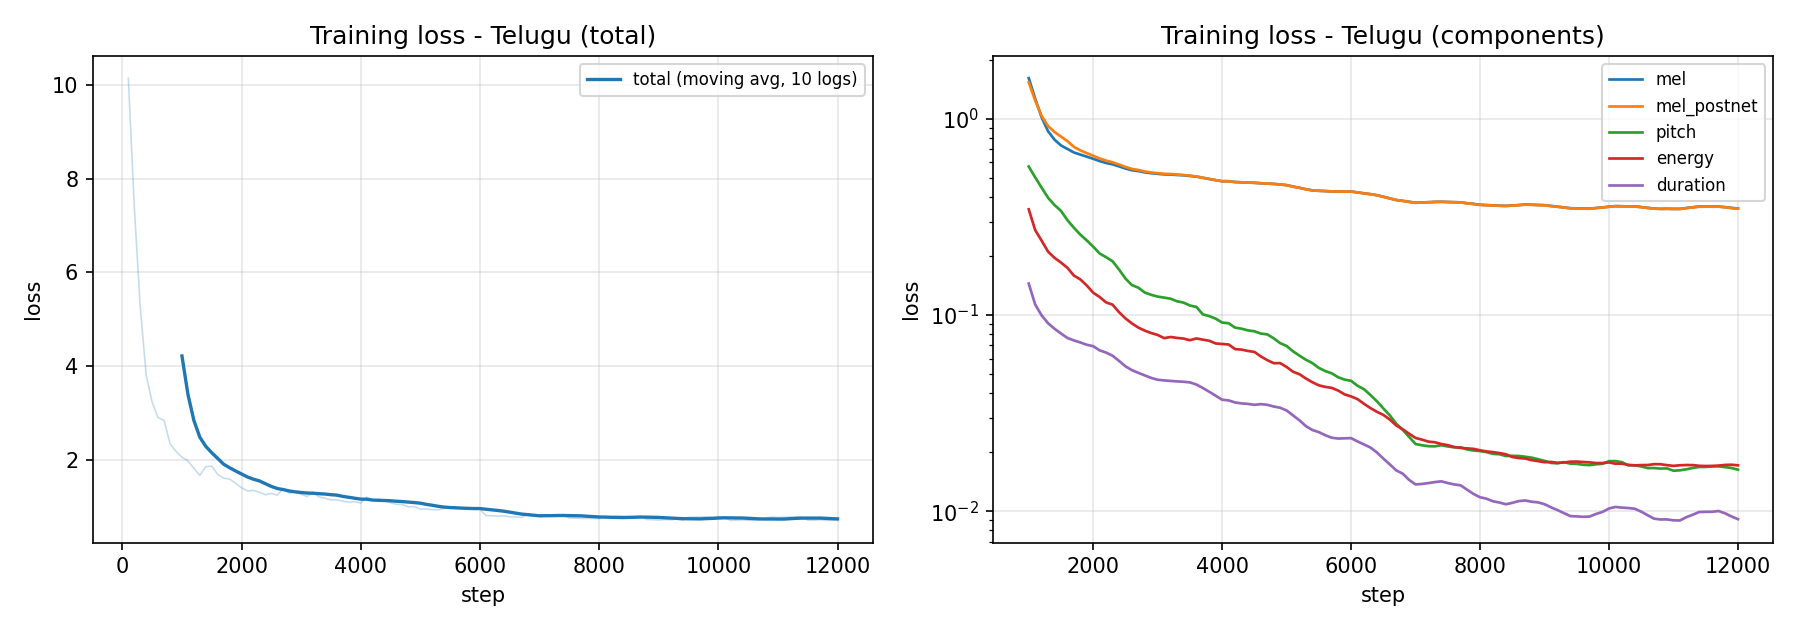

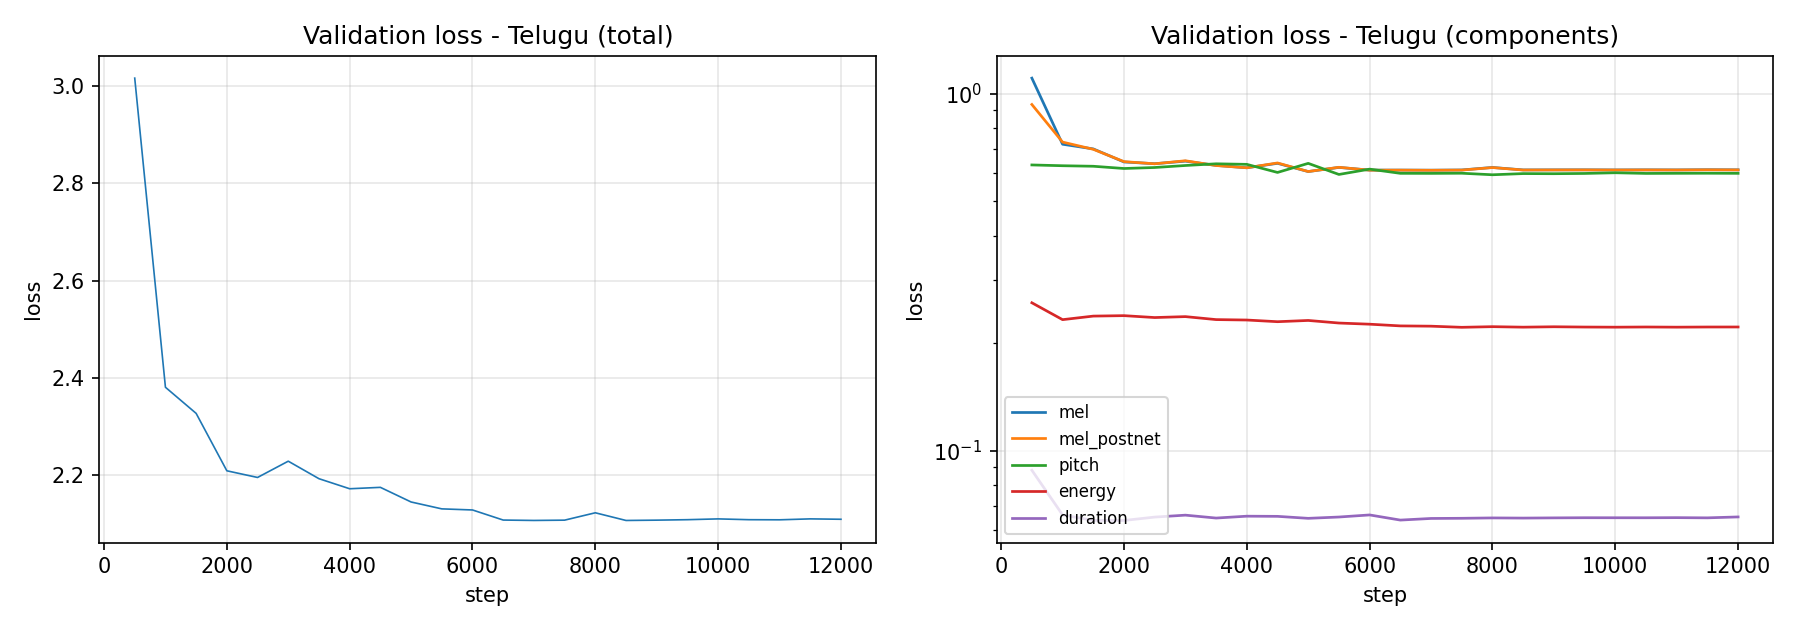

[2026-11-01 20:34:38 IST] finished in 2.0 s


In [7]:
%cd /content/project
!python scripts/plot_losses.py {LANG}
from IPython.display import Image, display
for f in ["training_loss.png", "validation_loss.png"]:
    display(Image(f"/content/project/Results/{LANG}/{f}"))

## Which checkpoint to keep

Validation loss is computed with the true durations, pitch and energy fed in, so it does not say how the
synthesised speech sounds. This synthesises 60 validation sentences from every checkpoint saved in this session
and transcribes them with Whisper. Lower word and character error rates mean more intelligible speech.

In [8]:
!python -W ignore scripts/asr_eval.py checkpoints {LANG} 2>&1 | grep -v -i warn

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
Removing weight norm...
60 sentences from val.txt
  1000  WER  38.0%  CER  33.5%  (1906 words)
  2000  WER  27.7%  CER  19.0%  (1906 words)
  3000  WER  24.6%  CER  15.2%  (1906 words)
  4000  WER  24.0%  CER  14.2%  (1906 words)
  5000  WER  26.7%  CER